In [ ]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
print("All Evaluation Libraries Imported Successfully!")

All Evaluation Libraries Imported Successfully!


In [ ]:
# Step 2: Load the clustering results
df_eval = pd.read_csv("../dataset/market_clusters.csv")
print("Clustering Results Loaded Successfully!")
print("\nDataset Shape:", df_eval.shape)
print("\nColumn Names:")
print(df_eval.columns.tolist())
print("\nFirst 5 Records:")
display(df_eval.head())

Clustering Results Loaded Successfully!

Dataset Shape: (14330, 14)

Column Names:
['state', 'district', 'market', 'commodity', 'avg_price', 'median_price', 'std_price', 'min_price', 'max_price', 'avg_arrival', 'median_arrival', 'total_arrival', 'total_records', 'cluster']

First 5 Records:


,state,district,market,commodity,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records,cluster
0,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.290909,0.25,9.60,33,1
1,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Green Gram(Moong)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.389394,0.35,12.85,33,1
2,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Tomato,4166.666667,3500.0,1820.027472,2000.0,7000.0,0.905556,0.70,8.15,9,1
3,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Turmeric,24818.181818,25000.0,527.644853,23000.0,25000.0,0.458485,0.30,15.13,33,1
4,Andaman and Nicobar,North and Middle Andaman,Mayabander Vegetable Market,Tomato,7400.000000,8000.0,894.427191,6000.0,8000.0,0.050000,0.05,0.25,5,1


In [ ]:
# Step 3: Load saved models
kmeans_model = joblib.load("../models/kmeans_model.pkl")
scaler = joblib.load("../models/scaler.pkl")
pca = joblib.load("../models/pca_model.pkl")
print("All Models Loaded Successfully!")
print("\nK-Means Model:", kmeans_model)
print("Scaler:", scaler)
print("PCA Model:", pca)

All Models Loaded Successfully!

K-Means Model: KMeans(n_clusters=2, n_init=10, random_state=42)
Scaler: StandardScaler()
PCA Model: PCA(n_components=2)


In [ ]:
# Step 4: Prepare features for evaluation
# Select the nine numerical features
clustering_features = [
    'avg_price',
    'median_price',
    'std_price',
    'min_price',
    'max_price',
    'avg_arrival',
    'median_arrival',
    'total_arrival',
    'total_records'
]
X_eval = df_eval[clustering_features].copy()

# Apply log transformation to the same eight features
log_features = [
    'avg_price',
    'median_price',
    'std_price',
    'min_price',
    'max_price',
    'avg_arrival',
    'median_arrival',
    'total_arrival'
]

for feature in log_features:
    X_eval[feature] = np.log1p(X_eval[feature])

# Apply the previously trained scaler
X_eval_scaled = scaler.transform(X_eval)

# Extract existing cluster labels
labels = df_eval['cluster'].values

print("Evaluation Data Prepared Successfully!")
print("\nFeature Shape:", X_eval.shape)
print("Scaled Feature Shape:", X_eval_scaled.shape)
print("Cluster Labels Shape:", labels.shape)
print("\nFirst 10 Cluster Labels:")
print(labels[:10])

Evaluation Data Prepared Successfully!

Feature Shape: (14330, 9)
Scaled Feature Shape: (14330, 9)
Cluster Labels Shape: (14330,)

First 10 Cluster Labels:
[1 1 1 1 1 0 1 1 0 1]


In [ ]:
# Step 5: Calculate Silhouette Score
sil_score = silhouette_score(
    X_eval_scaled,
    labels,
    sample_size=3000,
    random_state=42
)
print("Silhouette Score:", round(sil_score, 4))

Silhouette Score: 0.3065


In [ ]:
# Step 6: Calculate Davies-Bouldin Index
db_score = davies_bouldin_score(
    X_eval_scaled,
    labels
)
print("Davies-Bouldin Index:", round(db_score, 4))

Davies-Bouldin Index: 1.3122


In [ ]:
# Step 7: Calculate Calinski-Harabasz Score
ch_score = calinski_harabasz_score(
    X_eval_scaled,
    labels
)
print("Calinski-Harabasz Score:", round(ch_score, 4))

Calinski-Harabasz Score: 7165.3577


In [ ]:
# Step 8: Create evaluation summary
evaluation_results = pd.DataFrame({
    'Metric': [
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Score'
    ],
    'Score': [
        sil_score,
        db_score,
        ch_score
    ],
    'Interpretation': [
        'Higher is better',
        'Lower is better',
        'Higher is better'
    ]
})
print("Clustering Model Evaluation Summary:")
display(evaluation_results)

Clustering Model Evaluation Summary:


,Metric,Score,Interpretation
0,Silhouette Score,0.306468,Higher is better
1,Davies-Bouldin Index,1.312187,Lower is better
2,Calinski-Harabasz Score,7165.357718,Higher is better


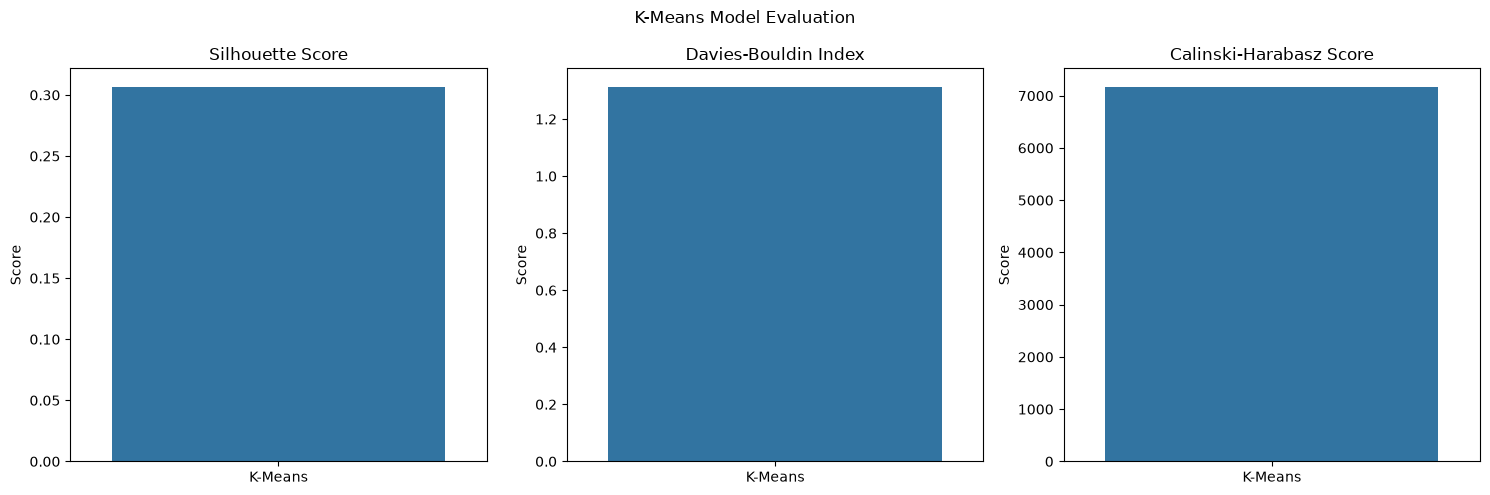

In [ ]:
# Step 9: Visualize evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.barplot(
    x=['K-Means'],
    y=[sil_score],
    ax=axes[0]
)
axes[0].set_title("Silhouette Score")
axes[0].set_ylabel("Score")
sns.barplot(
    x=['K-Means'],
    y=[db_score],
    ax=axes[1]
)
axes[1].set_title("Davies-Bouldin Index")
axes[1].set_ylabel("Score")
sns.barplot(
    x=['K-Means'],
    y=[ch_score],
    ax=axes[2]
)
axes[2].set_title("Calinski-Harabasz Score")
axes[2].set_ylabel("Score")

plt.suptitle("K-Means Model Evaluation")
plt.tight_layout()
plt.show()

In [ ]:
# Step 10: Final Model Evaluation Report

optimal_k = kmeans_model.n_clusters

print("=" * 50)
print("       MANDICLUSTER - MODEL EVALUATION")
print("=" * 50)

print("\nModel Information:")
print("Algorithm: K-Means Clustering")
print("Number of Clusters:", optimal_k)
print("Total Records:", len(df_eval))

print("\nEvaluation Metrics:")
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(db_score, 4))
print("Calinski-Harabasz Score:", round(ch_score, 4))

print("\nCluster Distribution:")
print(df_eval['cluster'].value_counts().sort_index())

print("\nModel Evaluation Completed Successfully!")
print("=" * 50)

       MANDICLUSTER - MODEL EVALUATION

Model Information:
Algorithm: K-Means Clustering
Number of Clusters: 2
Total Records: 14330

Evaluation Metrics:
Silhouette Score: 0.3065
Davies-Bouldin Index: 1.3122
Calinski-Harabasz Score: 7165.3577

Cluster Distribution:
cluster
0    7377
1    6953
Name: count, dtype: int64

Model Evaluation Completed Successfully!


In [ ]:

# Step 3: Extract graphs from saved Jupyter notebooks

import os
import json
import base64

# Destination folder
output_folder = "../visualizations"
os.makedirs(output_folder, exist_ok=True)

# Notebooks containing our graphs
notebooks = [
    "04_exploratory_data_analysis.ipynb",
    "06_clustering.ipynb",
    "07_model_evaluation.ipynb"
]

total_saved = 0

for notebook_name in notebooks:

    with open(notebook_name, "r", encoding="utf-8") as file:
        notebook = json.load(file)

    for cell_index, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] == "code":

            for output_index, output in enumerate(cell.get("outputs", [])):

                data = output.get("data", {})

                # Extract PNG graphs
                if "image/png" in data:

                    image_data = data["image/png"]

                    if isinstance(image_data, list):
                        image_data = "".join(image_data)

                    filename = (
                        notebook_name.replace(".ipynb", "")
                        + f"_cell_{cell_index}_graph_{output_index}.png"
                    )

                    filepath = os.path.join(output_folder, filename)

                    with open(filepath, "wb") as image_file:
                        image_file.write(base64.b64decode(image_data))

                    total_saved += 1

                # Extract SVG graphs
                if "image/svg+xml" in data:

                    svg_data = data["image/svg+xml"]

                    if isinstance(svg_data, list):
                        svg_data = "".join(svg_data)

                    filename = (
                        notebook_name.replace(".ipynb", "")
                        + f"_cell_{cell_index}_graph_{output_index}.svg"
                    )

                    filepath = os.path.join(output_folder, filename)

                    with open(filepath, "w", encoding="utf-8") as image_file:
                        image_file.write(svg_data)

                    total_saved += 1

print("Graph extraction completed!")
print("Total graph images saved:", total_saved)
print("Destination:", os.path.abspath(output_folder))



Graph extraction completed!
Total graph images saved: 39
Destination: c:\Users\thula\Desktop\Mandicluster\visualizations


In [ ]:
# Verify all saved graph files
import os
folder = "../visualizations"
files = os.listdir(folder)
print("Total Graph Files:", len(files))
print("\nSaved Graphs:")
for file in sorted(files):
    print(file)

Total Graph Files: 39

Saved Graphs:
04_exploratory_data_analysis_cell_10_graph_2.png
04_exploratory_data_analysis_cell_11_graph_2.png
04_exploratory_data_analysis_cell_12_graph_2.png
04_exploratory_data_analysis_cell_13_graph_0.png
04_exploratory_data_analysis_cell_14_graph_2.png
04_exploratory_data_analysis_cell_15_graph_2.png
04_exploratory_data_analysis_cell_16_graph_2.png
04_exploratory_data_analysis_cell_17_graph_2.png
04_exploratory_data_analysis_cell_18_graph_2.png
04_exploratory_data_analysis_cell_19_graph_2.png
04_exploratory_data_analysis_cell_20_graph_2.png
04_exploratory_data_analysis_cell_21_graph_2.png
04_exploratory_data_analysis_cell_22_graph_2.png
04_exploratory_data_analysis_cell_23_graph_2.png
04_exploratory_data_analysis_cell_24_graph_2.png
04_exploratory_data_analysis_cell_25_graph_0.png
04_exploratory_data_analysis_cell_26_graph_0.png
04_exploratory_data_analysis_cell_27_graph_2.png
04_exploratory_data_analysis_cell_28_graph_2.png
04_exploratory_data_analysis_cel

In [ ]:
# Step 4: Organize graphs into separate folders
import os
import shutil
base_folder = "../visualizations"
# Create separate folders
folders = {
    "04": "EDA",
    "06": "Clustering",
    "07": "Evaluation"
}
for folder_name in folders.values():
    os.makedirs(os.path.join(base_folder, folder_name), exist_ok=True)
# Move graph files into their respective folders
for filename in os.listdir(base_folder):

    source_path = os.path.join(base_folder, filename)

    if os.path.isfile(source_path):

        for prefix, folder_name in folders.items():

            if filename.startswith(prefix + "_"):
                destination = os.path.join(base_folder, folder_name, filename)

                shutil.move(source_path, destination)
                break

print("Graphs organized successfully!")
for folder_name in folders.values():
    folder_path = os.path.join(base_folder, folder_name)
    print(folder_name, ":", len(os.listdir(folder_path)), "files")

Graphs organized successfully!
EDA : 32 files
Clustering : 6 files
Evaluation : 1 files
